# Bed shear stress from the Reynolds stress (question 1b/1c)

This notebook determines the bed shear stress $\tau_b$ by **extrapolating the Reynolds stress to the bed**. The log-law method is in `Flowq1_LogFit_LogShear.ipynb`.

**Theory** (CIEM4000 Lecture 2, slides 14, 24, 25)
- In uniform open-channel flow the force balance gives a total shear stress that is **linear over the depth**, regardless of the flow regime:
  $\tau(z) = \rho g S (h - z) = \tau_b(1 - z/h)$.
- Reynolds averaging gives the Reynolds stress $\tau_R = -\rho\overline{u'w'}$. In hydraulic flows $|\rho\overline{u'w'}| \gg \mu\,d\bar u/dz$, except in the viscous sublayer. Therefore
$$\tau(z) = \mu\frac{d\bar u}{dz} - \rho\overline{u'w'} \approx -\rho\overline{u'w'} = \tau_b(1 - z/h).$$
- The slides use $w'$ for the vertical fluctuation; in this data set it is $v'$.
- **Expected sign:** $\overline{u'v'} < 0$, because downward-moving fluid comes from faster layers (sweeps, Q4) and upward-moving fluid from slower layers (ejections, Q2). So $-\overline{u'v'} > 0$.

**Data:** 14 files, each a time series at one fixed height $z/h$ (0.027–0.944). The data are dimensionless: $\tilde t = tU/h$, $\tilde u = u/U$, $\tilde v = v/U$ ($v$ positive upward). In dimensionless form the relation becomes
$$-\overline{\tilde u'\tilde v'} = \frac{\tau_b}{\rho U^2}(1 - z/h) = \left(\frac{u_*}{U}\right)^2(1 - z/h).$$

**Input values (assignment):** $h = 25$ m, $U = 1.5$ m/s, $\rho = 1025$ kg/m³, $\nu = 1.0\times10^{-6}$ m²/s.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

h, U, RHO, NU, KAPPA = 25.0, 1.5, 1025.0, 1.0e-6, 0.41

# data folder: next to the notebook, or one level up
DATA_DIR = next(p for p in [Path("Velocity files for FSI"), Path("../Velocity files for FSI")] if p.exists())
FILES = sorted(DATA_DIR.glob("Z_*.dat"))

# plot style (same as the log-law notebook)
BLUE, ORANGE = "#2a78d6", "#eb6834"
MUV_LABEL = r"$-\overline{\tilde u'\tilde v'} = -\overline{u'v'}/U^2$"
def style(ax, title):
    ax.set_xlabel(MUV_LABEL)
    ax.set_ylabel(r"$z/h$")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.grid(True, color="0.88", lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

print(len(FILES), "files in", DATA_DIR)

14 files in ..\Velocity files for FSI


## Step 1 — Reynolds stress per height

For every height the fluctuations are computed as $u' = \tilde u - \overline{\tilde u}$ and $v' = \tilde v - \overline{\tilde v}$, and the Reynolds stress as $\overline{u'v'} = \overline{u'\,v'}$. As a **convergence check**, $\overline{u'v'}$ is also computed separately for the first and the second half of each record. If the record is long enough, both halves give almost the same value.

In [2]:
def cov_uv(u, v):
    # Reynolds stress <u'v'> of one (part of a) record, fluctuations about its own mean
    return np.mean((u - u.mean()) * (v - v.mean()))

rows = []
for path in FILES:                                   # loop over the 14 files, not over samples
    d = pd.read_csv(path, sep=r"\s+", header=None, names=["t", "u", "v"])
    u, v = d["u"].to_numpy(), d["v"].to_numpy()
    half = len(u) // 2
    zh = round(float(path.stem.split("_")[1]) / 100, 4)
    rows.append({"z/h": zh, "z [m]": zh * h, "mean u~": u.mean(), "mean v~": v.mean(),
                 "<u'v'>": cov_uv(u, v), "-<u'v'>": -cov_uv(u, v),
                 "-<u'v'> 1st half": -cov_uv(u[:half], v[:half]),
                 "-<u'v'> 2nd half": -cov_uv(u[half:], v[half:])})

rs = pd.DataFrame(rows).sort_values("z/h").reset_index(drop=True)
rs["half diff [%]"] = 100 * (rs["-<u'v'> 2nd half"] - rs["-<u'v'> 1st half"]) / rs["-<u'v'>"]
rs.to_csv("reynolds_stats.csv", index=False)

zh  = rs["z/h"].to_numpy()
muv = rs["-<u'v'>"].to_numpy()
rs.style.format({"z/h": "{:.3f}", "z [m]": "{:.2f}", "mean u~": "{:.4f}", "mean v~": "{:.1e}",
                 "<u'v'>": "{:.5f}", "-<u'v'>": "{:.5f}", "-<u'v'> 1st half": "{:.5f}",
                 "-<u'v'> 2nd half": "{:.5f}", "half diff [%]": "{:+.1f}"})

,z/h,z [m],mean u~,mean v~,,-,- 1st half,- 2nd half,half diff [%]
0,0.027,0.68,0.4280,1.3e-06,-0.00319,0.00319,0.00306,0.00333,+8.4
1,0.073,1.82,0.6425,-9.6e-07,-0.00543,0.00543,0.00579,0.00506,-13.3
2,0.106,2.65,0.7109,-1.4e-06,-0.00556,0.00556,0.00582,0.00524,-10.4
3,0.168,4.20,0.8316,-2.9e-06,-0.00561,0.00561,0.00572,0.00547,-4.5
4,0.233,5.83,0.9199,-1.8e-06,-0.00506,0.00506,0.00525,0.00486,-7.9
5,0.297,7.42,0.9717,-6.0e-08,-0.00480,0.00480,0.00460,0.00497,+7.7
6,0.360,9.00,1.0202,-8.6e-07,-0.00401,0.00401,0.00409,0.00392,-4.1
7,0.424,10.60,1.0252,1.5e-07,-0.00387,0.00387,0.00388,0.00377,-2.8
8,0.488,12.20,1.0775,-1.9e-06,-0.00320,0.00320,0.00339,0.00302,-11.7
9,0.553,13.83,1.1110,-3.6e-06,-0.00247,0.00247,0.00254,0.00240,-5.7


**Convergence.** Up to $z/h \approx 0.62$ the two halves of each record differ by about 3–13 %. Near the surface the relative differences are large (up to ≈ 110 %), but only because $-\overline{u'v'}$ itself is almost zero there; in absolute terms the differences are ≤ 0.0004. So $\overline{u'v'}$ converges much more slowly than the mean velocity (which differed by < 4 %). The scatter of the points around a straight line in Step 2 is partly statistical.

## Step 2 — Plot $-\overline{u'v'}$ against $z/h$

The Reynolds stress is plotted with $-\overline{\tilde u'\tilde v'}$ on the horizontal axis and $z/h$ on the vertical axis (linear axes), like the $\tau/\tau_b$ plot on slide 14. According to the theory the points should lie on a straight line that reaches zero at the surface.

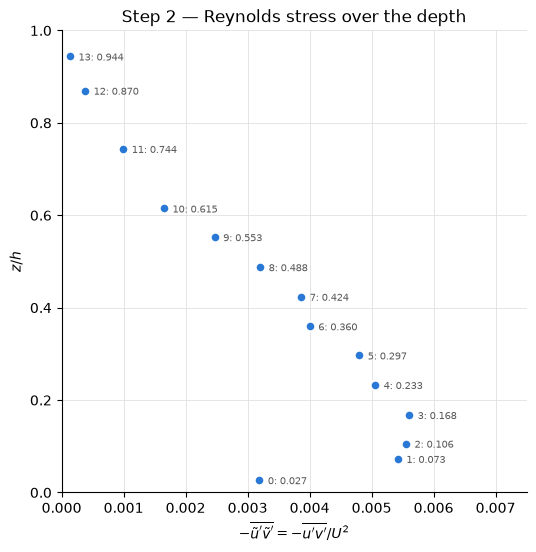

All values positive: True


In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(muv, zh, "o", color=BLUE, ms=7, mec="white", mew=1.5, zorder=3)
for i, (x, y) in enumerate(zip(muv, zh)):
    ax.annotate(f"{i}: {y:.3f}", (x, y), xytext=(6, -3), textcoords="offset points", fontsize=7, color="0.35")
ax.set_xlim(0, 0.0075)
style(ax, "Step 2 — Reynolds stress over the depth")
plt.show()
print("All values positive:", bool((muv > 0).all()))

**What is visible.**
- All values of $-\overline{u'v'}$ are **positive**, as expected.
- From $z/h \approx 0.1$ upwards they **decrease roughly linearly** to almost zero at the surface (≈ 0.0001 at $z/h = 0.944$).
- The **lowest point** ($z/h = 0.027$) lies clearly **below the trend**: about 0.0032 instead of ≈ 0.006. The second point ($z/h = 0.073$) is slightly low. This is expected close to a rough bed. The probe cannot resolve the smallest eddies there, and in the roughness layer part of the momentum is transferred by form drag on the roughness elements rather than by $\overline{u'v'}$.

## Step 3 — Linear fit

The data are fitted with a straight line $-\overline{\tilde u'\tilde v'} = c_0 + c_1\,(z/h)$ (`scipy.stats.linregress`). The **main fit** uses all 14 points. As a sensitivity check, the fit is repeated without the lowest point and without the 2 lowest points, because they deviate (Step 2). The theory predicts $c_1 = -c_0$, i.e. the line should reach zero at $z = h$.

,points used,c0,c1,-c1/c0,zero crossing z/h,R²,tau_b [N/m²]
fit,,,,,,,
all 14 points (main),14,0.00580,-0.00591,1.018,0.982,0.818,13.4
without lowest point,13,0.00648,-0.00699,1.078,0.927,0.975,14.9
without 2 lowest points,12,0.00666,-0.00726,1.091,0.917,0.981,15.4


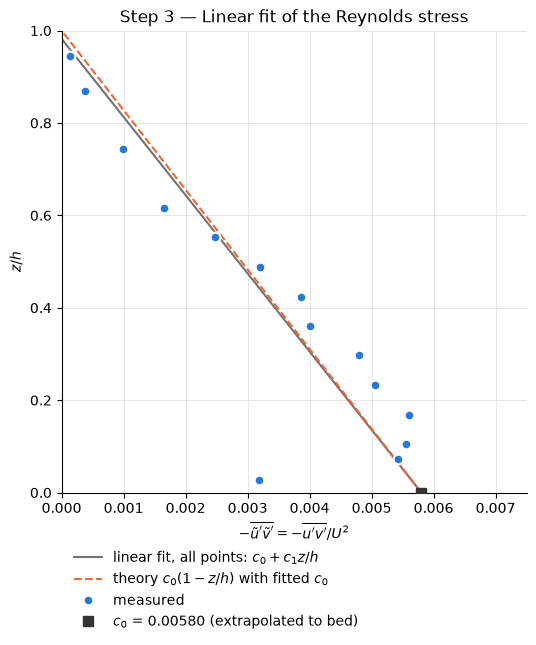

In [4]:
def rs_fit(mask):
    r = sps.linregress(zh[mask], muv[mask])
    c0, c1 = r.intercept, r.slope
    return dict(n=int(mask.sum()), c0=c0, se_c0=r.intercept_stderr, c1=c1, R2=r.rvalue**2,
                z_zero=-c0 / c1, tau=RHO * U**2 * c0)

fits = {"all 14 points (main)":   rs_fit(np.ones_like(zh, dtype=bool)),
        "without lowest point":   rs_fit(np.arange(len(zh)) >= 1),
        "without 2 lowest points": rs_fit(np.arange(len(zh)) >= 2)}

table = pd.DataFrame({k: {"points used": f["n"], "c0": f["c0"], "c1": f["c1"], "-c1/c0": -f["c1"] / f["c0"],
                          "zero crossing z/h": f["z_zero"], "R²": f["R2"], "tau_b [N/m²]": f["tau"]}
                      for k, f in fits.items()}).T
table.index.name = "fit"
display(table.style.format({"points used": "{:.0f}", "c0": "{:.5f}", "c1": "{:.5f}", "-c1/c0": "{:.3f}",
                            "zero crossing z/h": "{:.3f}", "R²": "{:.3f}", "tau_b [N/m²]": "{:.1f}"}))

main = fits["all 14 points (main)"]
zz = np.linspace(0, 1, 50)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(main["c0"] + main["c1"] * zz, zz, "-", color="0.45", lw=1.5,
        label=rf"linear fit, all points: $c_0 + c_1 z/h$")
ax.plot(main["c0"] * (1 - zz), zz, "--", color=ORANGE, lw=1.5,
        label=rf"theory $c_0(1 - z/h)$ with fitted $c_0$")
ax.plot(muv, zh, "o", color=BLUE, ms=7, mec="white", mew=1.5, zorder=3, label="measured")
ax.plot(main["c0"], 0, "s", color="0.2", ms=7, zorder=4, label=rf"$c_0$ = {main['c0']:.5f} (extrapolated to bed)")
ax.set_xlim(0, 0.0075)
style(ax, "Step 3 — Linear fit of the Reynolds stress")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), frameon=False)
plt.show()

## Step 4 — Bed shear stress (one calculation step)

The fit from Step 3 gives the intercept $c_0$: the value of $-\overline{\tilde u'\tilde v'}$ at the bed ($z = 0$). Because the data are dimensionless (scaled by $U^2$), $c_0 = \tau_b/(\rho U^2)$, so the bed shear stress follows from one calculation:

$$\tau_b = \rho\,U^2\,c_0 \qquad (\rho = 1025\ \text{kg/m}^3,\ U = 1.5\ \text{m/s})$$

As a check, the theory gives slope $c_1 = -c_0$, so $\tau_b$ can also be computed from the slope: $\tau_b = -\rho U^2 c_1$.

In [5]:
# c0, c1 and SE(c0) taken directly from the Step 3 main fit (no refit)
c0, se_c0, c1 = main["c0"], main["se_c0"], main["c1"]

tau_b  = RHO * U**2 * c0               # main result [N/m2]
se_tau = RHO * U**2 * se_c0            # uncertainty [N/m2]
u_star = np.sqrt(tau_b / RHO)          # friction velocity [m/s]
se_us  = 0.5 * (se_tau / tau_b) * u_star

tau_b_slope = -RHO * U**2 * c1         # check: theory c1 = -c0
diff_slope  = 100 * (tau_b_slope / tau_b - 1)

pd.DataFrame([
    {"quantity": "c0 (intercept)",                  "value": f"{c0:.5f}"},
    {"quantity": "c1 (slope)",                      "value": f"{c1:.5f}"},
    {"quantity": "tau_b from intercept [N/m²] (main)", "value": f"{tau_b:.1f} ± {se_tau:.1f}"},
    {"quantity": "tau_b from slope [N/m²] (check)", "value": f"{tau_b_slope:.1f}"},
    {"quantity": "difference slope vs intercept [%]", "value": f"{diff_slope:+.1f}"},
    {"quantity": "u* = sqrt(tau_b/rho) [m/s]",      "value": f"{u_star:.4f} ± {se_us:.4f}"},
]).style.hide(axis="index")

quantity,value
c0 (intercept),0.00580
c1 (slope),-0.00591
tau_b from intercept [N/m²] (main),13.4 ± 0.9
tau_b from slope [N/m²] (check),13.6
difference slope vs intercept [%],+1.8
u* = sqrt(tau_b/rho) [m/s],0.1143 ± 0.0040


## Step 5 — Comparison with the log-law fit (preparation for question 1c)

The log-law result is recomputed here from `profile_stats.csv`, exactly as in `Flowq1_LogFit_LogShear.ipynb` Step 3: a straight line through all 14 points of $\bar u/U$ against $\ln(z/h)$, $u_* = \kappa a U$, $\tau_b = \rho u_*^2$. Its uncertainty is the standard error of the slope $a$; the relative error in $\tau_b$ is twice that of $u_*$. The Reynolds-stress values ($u_*$, $	au_b$) are taken from Step 4.

In [6]:
ps = pd.read_csv("profile_stats.csv").sort_values("z/h")
lg = sps.linregress(np.log(ps["z/h"]), ps["u_mean"])
a, b = lg.slope, lg.intercept
log_us  = KAPPA * a * U
log_tau = RHO * log_us**2
log_se_us  = KAPPA * lg.stderr * U
log_se_tau = 2 * (lg.stderr / a) * log_tau
log_z0 = h * np.exp(-b / a)
print(f"Log-law fit (all 14 points): a = {a:.4f}, b = {b:.4f}, z0 = {log_z0:.3f} m")

comp = pd.DataFrame([
    {"method": "log-law fit, all 14 points", "u* [m/s]": log_us, "± u* [m/s]": log_se_us,
     "tau_b [N/m²]": log_tau, "± tau_b [N/m²]": log_se_tau},
    {"method": "Reynolds stress, all 14 points", "u* [m/s]": u_star, "± u* [m/s]": se_us,
     "tau_b [N/m²]": tau_b, "± tau_b [N/m²]": se_tau},
    {"method": "Reynolds stress, without 2 lowest points", "u* [m/s]": U * np.sqrt(fits["without 2 lowest points"]["c0"]),
     "± u* [m/s]": np.nan, "tau_b [N/m²]": fits["without 2 lowest points"]["tau"], "± tau_b [N/m²]": np.nan},
])
comp["Δ tau_b vs log law [%]"] = 100 * (comp["tau_b [N/m²]"] / log_tau - 1)
comp.style.hide(axis="index").format({"u* [m/s]": "{:.4f}", "± u* [m/s]": "{:.4f}", "tau_b [N/m²]": "{:.1f}",
                                      "± tau_b [N/m²]": "{:.1f}", "Δ tau_b vs log law [%]": "{:+.1f}"}, na_rep="–")

Log-law fit (all 14 points): a = 0.2142, b = 1.2123, z0 = 0.087 m


method,u* [m/s],± u* [m/s],tau_b [N/m²],± tau_b [N/m²],Δ tau_b vs log law [%]
"log-law fit, all 14 points",0.1317,0.0040,17.8,1.1,+0.0
"Reynolds stress, all 14 points",0.1143,0.0040,13.4,0.9,-24.8
"Reynolds stress, without 2 lowest points",0.1224,–,15.4,–,-13.7


### Draft discussion

> **⚠ PROPOSAL — adapt before using.** Draft text for question 1c, based on the numbers above.

The Reynolds-stress method gives a bed shear stress about 25 % lower than the log-law fit (≈ 13 vs ≈ 18 N/m²). The difference is much larger than the statistical uncertainty of either method (≈ 1 N/m²), so it must come from the assumptions behind the methods. Possible reasons:

- **Validity of the log law.** The log law is derived assuming $\tau \approx \tau_b$, which only holds close to the bed. Fitting all 14 points includes the upper part of the water column (wake region), and this changes the slope $a$ and therefore $u_*$.
- **Sensitivity to the slope.** $\tau_b \propto u_*^2 \propto a^2$, so any error in the slope is doubled in $\tau_b$. In the Reynolds-stress method $\tau_b$ is proportional to $c_0$, and the uncertainty lies mainly in the extrapolation to $z = 0$.
- **Measurement limitations near the bed.** The probe's sampling volume cannot resolve the smallest eddies close to the bed, so $-\overline{u'v'}$ is underestimated there; the lowest point is clearly too low. Leaving out the 2 lowest points raises the Reynolds-stress estimate to ≈ 15 N/m². In addition, a small misalignment of the probe mixes part of $\overline{u'^2}$ into $\overline{u'v'}$.
- **Non-uniform flow.** If the flow is not exactly uniform, $\tau$ is not exactly linear over the depth, and the extrapolation to the bed is biased.
- **Von Kármán constant.** The assumed $\kappa = 0.41$ only enters the log-law method ($u_* = \kappa a U$); the Reynolds-stress method does not depend on it.

## Summary

- **Fit:** the linear fit of $-\overline{\tilde u'\tilde v'}$ over all 14 points, extrapolated to the bed, gives $c_0 = (u_*/U)^2 = 0.00580 \pm 0.00041$.
- **Result:** with $U = 1.5$ m/s and $\rho = 1025$ kg/m³ this gives
  - $u_* = 0.114 \pm 0.004$ m/s
  - $\tau_b = 13.4 \pm 0.9$ N/m²
- **Check against theory:** the fitted line reaches zero at $z/h = 0.98$, close to the theoretical $z = h$.
- **Sensitivity to the lowest points:** without the 2 lowest points, which are too low near the rough bed, $\tau_b$ rises to ≈ 15.4 N/m².
- **Comparison with the log-law fit:** the log-law fit over all 14 points gives $\tau_b = 17.8$ N/m². The Reynolds-stress method is therefore about 25 % lower (14 % lower without the 2 lowest points). See Step 5 for possible reasons.